**Nombre de Proyecto: Proyecto EdTech Learning Analytics Parte 9**

**Numero de grupo: 2**

**Integrante a cargo: Luis Alonso Hernandez Mundo**

**Carnet: 039025**

**Tipo de libro: Libro python para prediccion de datos con ia**

**Fecha de creacion: 27/10/2026**

**Version de libro: 1.0**

**Razon del porque escogimos predecir el riesgo_academico:**
"riesgo_academico" es el nivel de riesgo de que el estudiante repruebe la materia del ciclo actual (o tenga un desempeño academico deficiente), sintetizado en tres niveles:
- Bajo,
- Medio,
- Alto

a partir de sus notas, asistencia, cumplimiento de tareas, participación en el LMS y observaciones docentes.

In [1]:
# Creacion de carpeteo
!mkdir -p datos/procesados
!mkdir -p datos/externos
!mkdir -p documentos

print("Carpetas creadas")

Carpetas creadas


In [2]:
# Importacion de librerias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Scikit-learn: librería de Machine Learning
from sklearn.dummy import DummyRegressor       # Para el baseline
from sklearn.linear_model import LinearRegression  # Modelo simple
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Configuracion de semilla para reproducibilidad
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Configuracion de estilo de matplotlib
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

print("Librerías importadas")
print(f"   - pandas: {pd.__version__}")
print(f"   - numpy: {np.__version__}")
print(f"   - scikit-learn: {__import__('sklearn').__version__}")
print(f"\nSemilla de reproducibilidad: {RANDOM_STATE}")

Librerías importadas
   - pandas: 2.2.3
   - numpy: 2.1.3
   - scikit-learn: 1.6.1

Semilla de reproducibilidad: 42


In [3]:
# Carga de dataset a utilizar
BASE = Path('/content')
from google.colab import files

print("Dataset a usar:")
print("   - dataset_limpio_Proyecto_EdTech_Learning_Analytics.csv")

uploaded = files.upload()

for nombre, contenido in uploaded.items():
    destino = BASE / 'datos' / 'procesados' / nombre
    destino.write_bytes(contenido)
    print(f"  {nombre} → datos/procesados/")

Dataset a usar:
   - dataset_limpio_Proyecto_EdTech_Learning_Analytics.csv


Saving dataset_limpio_Proyecto_EdTech_Learning_Analytics.csv to dataset_limpio_Proyecto_EdTech_Learning_Analytics.csv
  dataset_limpio_Proyecto_EdTech_Learning_Analytics.csv → datos/procesados/


In [4]:
# Lectura y verificacion de datos de csv recien cargado
nombre_archivo = list(uploaded.keys())[0]
ruta_csv = BASE / 'datos' / 'procesados' / nombre_archivo

df = pd.read_csv(ruta_csv)

print(f"Archivo cargado: {nombre_archivo}")
print(f"Dimensiones: {df.shape[0]} filas x {df.shape[1]} columnas")

print("\nINFORMACIÓN DEL DATASET:")
print("=" * 60)
df.info()

print("\nVALORES NULOS POR COLUMNA:")
print(df.isnull().sum())

print(f"\nDIMENSIONES:")
print(f"  Filas: {df.shape[0]}")
print(f"  Columnas: {df.shape[1]}")

print(f"\nESTADÍSTICAS DE nota_final:")
print(df['nota_final'].describe().to_string())

Archivo cargado: dataset_limpio_Proyecto_EdTech_Learning_Analytics.csv
Dimensiones: 1000 filas x 43 columnas

INFORMACIÓN DEL DATASET:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 43 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   carnet                  1000 non-null   object 
 1   nombres                 1000 non-null   object 
 2   apellidos               1000 non-null   object 
 3   fecha_nacimiento        1000 non-null   object 
 4   edad                    1000 non-null   int64  
 5   sexo                    1000 non-null   object 
 6   facultad                1000 non-null   object 
 7   carrera                 1000 non-null   object 
 8   anio_ingreso            1000 non-null   int64  
 9   ciclo_actual            1000 non-null   int64  
 10  turno                   1000 non-null   object 
 11  municipio_residencia    1000 non-null   object 
 12  zona        

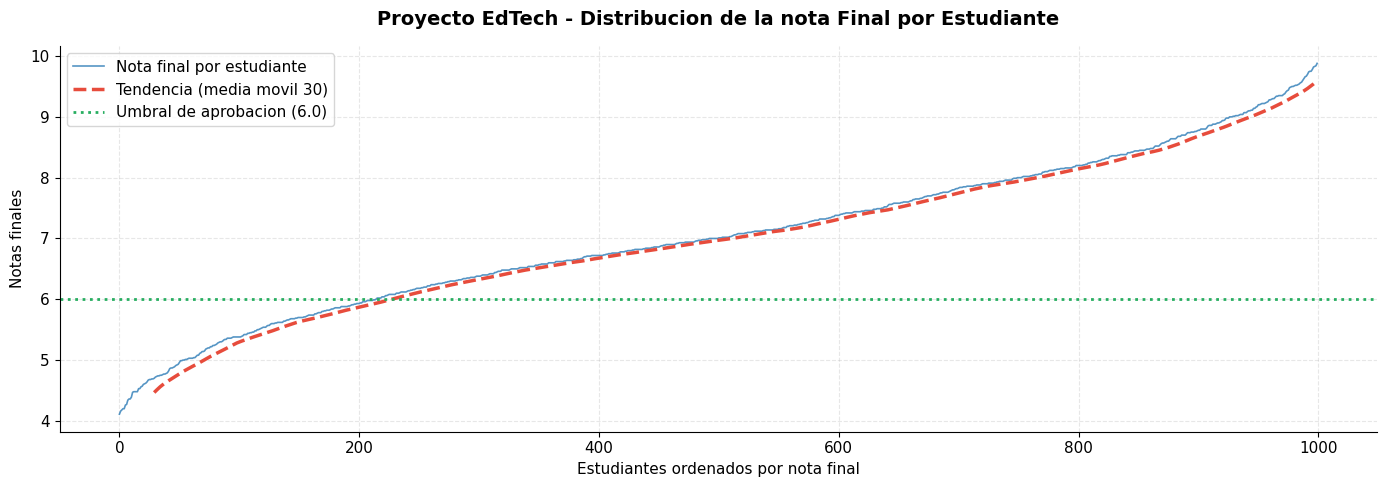


OBSERVACIONES DE LA DISTRIBUCIÓN:
   • Nota minima:      4.11
   • Nota maxima:      9.88
   • Nota promedio:    7.06
   • Nota mediana:     7.00
   • Desviacion estandar:   1.26
   • % reprobados (<6):21.4 %


In [5]:
# GRAFICO 1: Distribucion de nota_final por estudiante
fig, ax = plt.subplots(figsize=(14, 5))

# Ordenamos por nota_final para que la seria tenga sentido visual
df_plot = df.sort_values('nota_final').reset_index(drop=True)

ax.plot(df_plot.index, df_plot['nota_final'],
        color='#2c7bb6', linewidth=1.2, alpha=0.8,
        label='Nota final por estudiante')

# Linea de tendencia (media movil de 30 estudiantes)
df_plot['tendencia_30'] = df_plot['nota_final'].rolling(window=30).mean()
ax.plot(df_plot.index, df_plot['tendencia_30'],
        color='#e74c3c', linewidth=2.5, linestyle='--',
        label='Tendencia (media movil 30)')

# Umbral de aprobacion
ax.axhline(y=6.0, color='#27ae60', linestyle=':', linewidth=2,
           label='Umbral de aprobacion (6.0)')

ax.set_title('Proyecto EdTech - Distribucion de la nota Final por Estudiante',
             fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Estudiantes ordenados por nota final', fontsize=11)
ax.set_ylabel('Notas finales', fontsize=11)
ax.grid(True, alpha=0.3, linestyle='--')
ax.legend(loc='upper left')

plt.tight_layout()
plt.show()

print("\nOBSERVACIONES DE LA DISTRIBUCIÓN:")
print(f"   • Nota minima:      {df['nota_final'].min():.2f}")
print(f"   • Nota maxima:      {df['nota_final'].max():.2f}")
print(f"   • Nota promedio:    {df['nota_final'].mean():.2f}")
print(f"   • Nota mediana:     {df['nota_final'].median():.2f}")
print(f"   • Desviacion estandar:   {df['nota_final'].std():.2f}")
print(f"   • % reprobados (<6):{(df['nota_final'] < 6.0).mean()*100:.1f} %")

Distribucion de riesgo_academico segun trabaja (%):
riesgo_academico  Bajo  Medio  Alto
trabaja                            
No                20.1   33.4  46.5
Sí                22.1   31.1  46.9


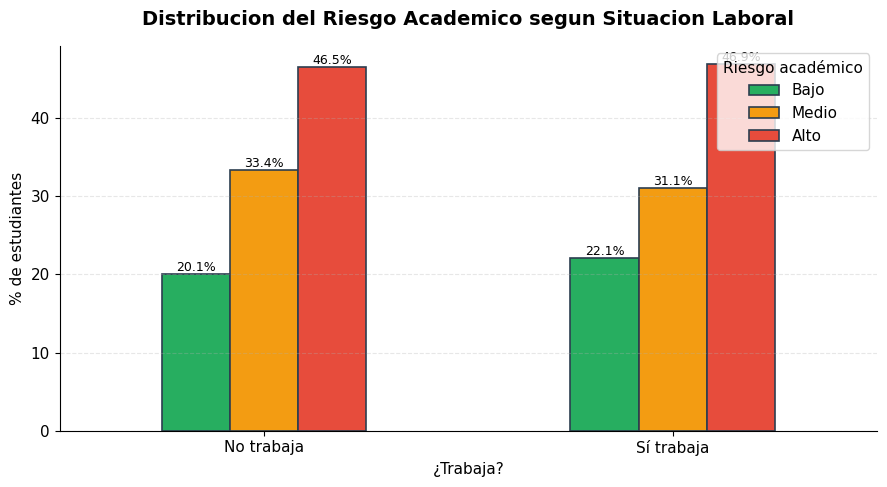


PATRONES OBSERVADOS:
   Riesgo Bajo: No trabaja 20.1% | Sí trabaja 22.1%
   Riesgo Medio: No trabaja 33.4% | Sí trabaja 31.1%
   Riesgo Alto: No trabaja 46.5% | Sí trabaja 46.9%

HIPÓTESIS:
Si la proporción de riesgo Alto es mayor entre quienes trabajan,
la situación laboral puede llegar a ser un predictor útil del riesgo académico.


In [ ]:
# DISTRIBUCION DE RIESGO_ACADEMICO SEGUN SITUACION LABORAL
orden = ['Bajo', 'Medio', 'Alto']
colores = {'Bajo': '#27ae60', 'Medio': '#f39c12', 'Alto': '#e74c3c'}

tabla = pd.crosstab(df['trabaja'], df['riesgo_academico'], normalize='index') * 100
tabla = tabla.reindex(columns=orden)
print("Distribucion de riesgo_academico segun trabaja (%):")
print("=" * 55)
print(tabla.round(1))

# Gráfico de barras agrupadas
fig, ax = plt.subplots(figsize=(9, 5))
tabla.plot(kind='bar', ax=ax,
           color=[colores[c] for c in orden],
           edgecolor='#2c3e50', linewidth=1.2)

ax.set_title('Distribucion del Riesgo Academico segun Situacion Laboral',
             fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('¿Trabaja?', fontsize=11)
ax.set_ylabel('% de estudiantes', fontsize=11)
ax.set_xticklabels(['No trabaja', 'Sí trabaja'], rotation=0)
ax.legend(title='Riesgo académico', loc='upper right')
ax.grid(True, alpha=0.3, axis='y', linestyle='--')

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', fontsize=9)

plt.tight_layout()
plt.show()

print("\nPATRONES OBSERVADOS:")
print("=" * 55)
for nivel in ['Bajo', 'Medio', 'Alto']:
    pct_no = tabla.loc['No', nivel]
    pct_si = tabla.loc['Sí', nivel]
    print(f"   Riesgo {nivel}: No trabaja {pct_no:.1f}% | Sí trabaja {pct_si:.1f}%")

print("\nHIPÓTESIS:")
print("Si la proporción de riesgo Alto es mayor entre quienes trabajan,")
print("la situación laboral puede llegar a ser un predictor útil del riesgo académico.")

In [7]:
# DEFINIR VARIABLES PREDICTORAS (X) Y OBJETIVO (y)

# Variables que si estan disponibles al momento de predecir
features = [
    # --- Variables Numéricas ---
    "edad", "anio_ingreso", "ciclo_actual", "horas_trabajo_semana",
    "faltas_consecutivas", "tareas_entregadas", "tareas_tarde",
    "porcentaje_asistencia", "actividad_lms", "total_observaciones",
    "semana_evaluacion",

    # --- Variables Categóricas ---
    "sexo", "facultad", "carrera", "turno", "municipio_residencia",
    "zona", "acceso_internet_casa", "beca", "materia", "participacion_nivel",

    # --- Variables Booleanas ---
    "trabaja", "requiere_seguimiento", "es_fin_semana",
]

# Aqui puse esto para verificar que todas las columnas existan
faltantes = [f for f in features if f not in df.columns]
if faltantes:
    print(f"Columnas no encontradas: {faltantes}")
else:
    print("Todas las features existen")

X = df[features]
y = df["riesgo_academico"]

print("\nVARIABLES DEFINIDAS:")
print("=" * 60)
print(f"Variables predictoras (X): {len(features)}")
for i, f in enumerate(features, 1):
    print(f"   {i:>2}. {f}")
print(f"\nVariable objetivo (y): riesgo_academico")
print(f"\nDimensiones:")
print(f"   X: {X.shape}")
print(f"   y: {y.shape}")
print(f"\nBalance del target:")
print(y.value_counts())

Todas las features existen

VARIABLES DEFINIDAS:
Variables predictoras (X): 24
    1. edad
    2. anio_ingreso
    3. ciclo_actual
    4. horas_trabajo_semana
    5. faltas_consecutivas
    6. tareas_entregadas
    7. tareas_tarde
    8. porcentaje_asistencia
    9. actividad_lms
   10. total_observaciones
   11. semana_evaluacion
   12. sexo
   13. facultad
   14. carrera
   15. turno
   16. municipio_residencia
   17. zona
   18. acceso_internet_casa
   19. beca
   20. materia
   21. participacion_nivel
   22. trabaja
   23. requiere_seguimiento
   24. es_fin_semana

Variable objetivo (y): riesgo_academico

Dimensiones:
   X: (1000, 24)
   y: (1000,)

Balance del target:
riesgo_academico
Alto     467
Medio    322
Bajo     211
Name: count, dtype: int64


In [8]:
# DIVISIÓN DE DATOS (70 / 15 / 15) — split estratificado
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

# Paso 1: 70% train, 30% temporal
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

# Paso 2: del 30% temporal → 15% val + 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_temp
)

print("DIVISIÓN DE DATOS (70 / 15 / 15)")
print("=" * 60)
print(f"Total de registros: {len(X)}")
print(f"Entrenamiento: {len(X_train):>4} registros ({len(X_train)/len(X)*100:.0f}%)")
print(f"Validación:    {len(X_val):>4} registros ({len(X_val)/len(X)*100:.0f}%)")
print(f"Prueba:        {len(X_test):>4} registros ({len(X_test)/len(X)*100:.0f}%)")

print(f"\nBalance del riesgo_academico en cada conjunto:")
print(f"   Train: {y_train.value_counts(normalize=True).round(3).to_dict()}")
print(f"   Val:   {y_val.value_counts(normalize=True).round(3).to_dict()}")
print(f"   Test:  {y_test.value_counts(normalize=True).round(3).to_dict()}")

print(f"\nVERIFICACIÓN:")
print(f"   ¿Train + Val + Test = Total? {len(X_train)+len(X_val)+len(X_test) == len(X)}")
print(f"   ¿Sin solapamiento? {len(set(X_train.index) & set(X_test.index)) == 0}")

DIVISIÓN DE DATOS (70 / 15 / 15)
Total de registros: 1000
Entrenamiento:  700 registros (70%)
Validación:     150 registros (15%)
Prueba:         150 registros (15%)

Balance del riesgo_academico en cada conjunto:
   Train: {'Alto': 0.467, 'Medio': 0.321, 'Bajo': 0.211}
   Val:   {'Alto': 0.467, 'Medio': 0.32, 'Bajo': 0.213}
   Test:  {'Alto': 0.467, 'Medio': 0.327, 'Bajo': 0.207}

VERIFICACIÓN:
   ¿Train + Val + Test = Total? True
   ¿Sin solapamiento? True


In [9]:
# 5.4.1 BASELINE (DummyClassifier)
# Target: riesgo_academico (clasificacion multiclase)
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score)

# Estrategia: predecir siempre la clase mas frecuente del train
baseline = DummyClassifier(strategy="most_frequent", random_state=42)
baseline.fit(X_train, y_train)

pred_baseline = baseline.predict(X_test)

# Metricas de clasificación (weighted y macro para ver el desbalance)
acc_base      = accuracy_score(y_test, pred_baseline)
prec_weighted = precision_score(y_test, pred_baseline, average='weighted', zero_division=0)
rec_weighted  = recall_score(y_test, pred_baseline, average='weighted', zero_division=0)
f1_weighted   = f1_score(y_test, pred_baseline, average='weighted', zero_division=0)

prec_macro    = precision_score(y_test, pred_baseline, average='macro', zero_division=0)
rec_macro     = recall_score(y_test, pred_baseline, average='macro', zero_division=0)
f1_macro      = f1_score(y_test, pred_baseline, average='macro', zero_division=0)

print("BASELINE (clase mas frecuente del entrenamiento)")
print("=" * 60)
print(f"Clase predicha siempre: '{y_train.mode()[0]}'")
print(f"Frecuencia en train:    {y_train.value_counts(normalize=True).max()*100:.1f} %")
print(f"\nMÉTRICAS DEL BASELINE (TEST):")
print(f"   Accuracy:        {acc_base:.4f}")
print(f"   Precision (W):   {prec_weighted:.4f}")
print(f"   Recall (W):      {rec_weighted:.4f}")
print(f"   F1 (W):          {f1_weighted:.4f}")
print(f"   Precision (M):   {prec_macro:.4f}  ← macro")
print(f"   Recall (M):      {rec_macro:.4f}   ← macro")
print(f"   F1 (M):          {f1_macro:.4f}    ← macro")

BASELINE (clase mas frecuente del entrenamiento)
Clase predicha siempre: 'Alto'
Frecuencia en train:    46.7 %

MÉTRICAS DEL BASELINE (TEST):
   Accuracy:        0.4667
   Precision (W):   0.2178
   Recall (W):      0.4667
   F1 (W):          0.2970
   Precision (M):   0.1556  ← macro
   Recall (M):      0.3333   ← macro
   F1 (M):          0.2121    ← macro


In [17]:
# ENTRENAR REGRESION LOGISTICA (con imputacion de nulos de dos filas y con class_weight)
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, confusion_matrix,
                              classification_report)
import pandas as pd
import numpy as np

RANDOM_STATE = 42

num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object', 'bool']).columns.tolist()

preprocesador = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ]), num_cols),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ]), cat_cols),
])

# Búsqueda de C
print("BÚSQUEDA DE HIPERPARÁMETRO C (validación):")
print("=" * 60)
mejor_C, mejor_acc = None, 0
for C in [0.01, 0.1, 1, 10, 100]:
    m = Pipeline([
        ('prep', preprocesador),
        ('clf', LogisticRegression(
            C=C, max_iter=2000, multi_class='multinomial',
            class_weight='balanced', random_state=RANDOM_STATE,
        )),
    ])
    m.fit(X_train, y_train)
    acc_val = m.score(X_val, y_val)
    print(f"   C = {C:>6}: accuracy validación = {acc_val:.4f}")
    if acc_val > mejor_acc:
        mejor_acc, mejor_C = acc_val, C

print(f"\nMejor C = {mejor_C} (accuracy val = {mejor_acc:.4f})")

# Reentrenar con train + val
X_train_final = pd.concat([X_train, X_val])
y_train_final = pd.concat([y_train, y_val])

modelo = Pipeline([
    ('prep', preprocesador),
    ('clf', LogisticRegression(
        C=mejor_C, max_iter=2000, multi_class='multinomial',
        class_weight='balanced', random_state=RANDOM_STATE,
    )),
])
modelo.fit(X_train_final, y_train_final)
print(f"\nModelo final entrenado con {len(X_train_final)} registros")

# Predicciones
y_pred = modelo.predict(X_test)
y_prob = modelo.predict_proba(X_test)

# Métricas
acc  = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average='weighted', zero_division=0)
rec  = recall_score(y_test, y_pred, average='weighted', zero_division=0)
f1   = f1_score(y_test, y_pred, average='weighted', zero_division=0)
auc  = roc_auc_score(y_test, y_prob, multi_class='ovr', average='weighted')

# Métricas macro (importante por el desbalance)
f1_macro = f1_score(y_test, y_pred, average='macro', zero_division=0)

print("\nMÉTRICAS DEL MODELO (TEST):")
print("=" * 60)
print(f"   Accuracy:  {acc:.4f}")
print(f"   Precision: {prec:.4f}  (weighted)")
print(f"   Recall:    {rec:.4f}  (weighted)")
print(f"   F1:        {f1:.4f}  (weighted)")
print(f"   F1 (macro):{f1_macro:.4f}  ← más honesto con desbalance")
print(f"   ROC-AUC:   {auc:.4f}  (OvR weighted)")

print("\nReporte por clase:")
print(classification_report(y_test, y_pred))

print("Matriz de confusión (3×3):")
cm = confusion_matrix(y_test, y_pred, labels=modelo.classes_)
print(pd.DataFrame(cm, index=modelo.classes_, columns=modelo.classes_))

BÚSQUEDA DE HIPERPARÁMETRO C (validación):
   C =   0.01: accuracy validación = 0.3267
   C =    0.1: accuracy validación = 0.3267


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


   C =      1: accuracy validación = 0.3533
   C =     10: accuracy validación = 0.3467
   C =    100: accuracy validación = 0.3467

Mejor C = 1 (accuracy val = 0.3533)


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(



Modelo final entrenado con 850 registros

MÉTRICAS DEL MODELO (TEST):
   Accuracy:  0.3400
   Precision: 0.3716  (weighted)
   Recall:    0.3400  (weighted)
   F1:        0.3495  (weighted)
   F1 (macro):0.3154  ← más honesto con desbalance
   ROC-AUC:   0.4993  (OvR weighted)

Reporte por clase:
              precision    recall  f1-score   support

        Alto       0.52      0.39      0.44        70
        Bajo       0.17      0.19      0.18        31
       Medio       0.29      0.37      0.32        49

    accuracy                           0.34       150
   macro avg       0.33      0.32      0.32       150
weighted avg       0.37      0.34      0.35       150

Matriz de confusión (3×3):
       Alto  Bajo  Medio
Alto     27    17     26
Bajo      7     6     18
Medio    18    13     18


**Conclusiones del modelo de regresion logistica previo:**

**Que se hizo?**

En este experimento se entrenó una Regresión Logística multinomial usando únicamente las 24 variables conductuales y demográficas (asistencia, tareas entregadas, tareas tardías, actividad en el LMS, observaciones docentes, contexto socioeconómico, demografía), excluyendo deliberadamente las notas (nota_teoria, nota_laboratorio, nota_final, promedio_academico, materia_reprobada). El objetivo era medir si es posible predecir el nivel de riesgo académico antes de que el estudiante sea evaluado, es decir, en una etapa temprana del ciclo.


**Como funciona el bloque de codigo:**

1: define un ColumnTransformer que imputa nulos numéricos con la mediana y categóricos con la moda, y luego escala/one-hot-encodea;

2: busca el hiperparámetro de regularización C en el conjunto de validación probando cinco valores (0.01, 0.1, 1, 10, 100);

3: reentrena con la unión de entrenamiento y validación (850 registros) usando el mejor C;

4: genera predicciones y probabilidades sobre el conjunto de prueba (150 registros); y

5: calcula las métricas de clasificación (accuracy, precision, recall, F1 weighted, F1 macro, ROC-AUC) junto con el reporte por clase y la matriz de confusión 3×3. Se incorporó class_weight='balanced' para compensar el desbalance del target (~47 % Alto / 33 % Medio / 20 % Bajo).

La búsqueda de C en validación seleccionó C = 1 con un accuracy de validación de 0.3533. Sin embargo, en el conjunto de prueba el modelo obtuvo accuracy = 0.3400, F1 macro = 0.3154 y ROC-AUC = 0.4993. El accuracy es inferior al del baseline (0.4667) y el ROC-AUC es estadísticamente equivalente al azar (0.50), lo que indica que el modelo no distingue las tres clases. La matriz de confusión confirma esta conclusión: de 70 estudiantes con riesgo Alto real, solo 27 fueron correctamente clasificados (38.6 %); de 31 con riesgo Bajo, solo 6 (19.4 %); y de 49 con riesgo Medio, solo 18 (36.7 %). Los errores se distribuyen de forma casi uniforme entre las clases, sin un patrón discriminativo claro.

**Porque fallo este modelo?**

Porque el modelo no tenia la información necesaria. El target riesgo_academico se calcula a partir del desempeño en evaluaciones, y al excluir las notas, las variables conductuales restantes no contienen señal suficiente para discriminar el riesgo. El class_weight='balanced' no puede compensar esta ausencia de señal: solo redistribuye los errores, lo que explica que el accuracy (0.34) sea incluso inferior al del baseline (0.4667).

In [19]:
# EXPERIMENTO Y TEST 1: LogisticRegression sin class_weight
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                              confusion_matrix, classification_report)
import pandas as pd
import numpy as np

RANDOM_STATE = 42

num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object', 'bool']).columns.tolist()

preprocesador = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ]), num_cols),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ]), cat_cols),
])

modelo_sin_peso = Pipeline([
    ('prep', preprocesador),
    ('clf', LogisticRegression(
        C=1, max_iter=2000,
        # class_weight='balanced',   Esto se ha removido a proposito
        random_state=RANDOM_STATE,
    )),
])
modelo_sin_peso.fit(X_train, y_train)

y_pred_2 = modelo_sin_peso.predict(X_test)
y_prob_2 = modelo_sin_peso.predict_proba(X_test)

print("MODELO sin class_weight:")
print("=" * 60)
print(f"   Accuracy:  {accuracy_score(y_test, y_pred_2):.4f}")
print(f"   F1 macro:  {f1_score(y_test, y_pred_2, average='macro', zero_division=0):.4f}")
print(f"   ROC-AUC:   {roc_auc_score(y_test, y_prob_2, multi_class='ovr', average='weighted'):.4f}")
print("\nReporte por clase:")
print(classification_report(y_test, y_pred_2))

MODELO SIN class_weight:
   Accuracy:  0.4067
   F1 macro:  0.3114
   ROC-AUC:   0.5196

Reporte por clase:
              precision    recall  f1-score   support

        Alto       0.46      0.69      0.55        70
        Bajo       0.33      0.10      0.15        31
       Medio       0.27      0.20      0.23        49

    accuracy                           0.41       150
   macro avg       0.36      0.33      0.31       150
weighted avg       0.37      0.41      0.36       150



**Interpretacion de experimento 1**

Modelo sin notas: no sirve
Accuracy 0.4067 = 0.4667 del baseline eso quiere decir que está peor que adivinar.

ROC-AUC: 0.5196 ≈ 0.50 (Quiere decir que el modelo es tan bueno como lanzar una moneda, con un rendimiento muy muy pobre, siendo este modelo "Fallido por motivos de clasificacion")

F1 macro 0.31: Esto confirma que no distingue las 3 clases.

Conclusión: las variables conductuales y demográficas (sin notas) no son suficientes para predecir riesgo_academico. La etiqueta depende de las notas, y sin ellas no hay señal.


In [20]:
# EXPERIMENTO 2: LogisticRegression CON notas
from sklearn.model_selection import train_test_split

features_con_notas = features + [
    "nota_teoria", "nota_laboratorio", "nota_final",
    "promedio_academico", "materia_reprobada",
]

X_B = df[features_con_notas]
y_B = df["riesgo_academico"]

X_B_train, X_B_temp, y_B_train, y_B_temp = train_test_split(
    X_B, y_B, test_size=0.30, random_state=RANDOM_STATE, stratify=y_B
)
X_B_val, X_B_test, y_B_val, y_B_test = train_test_split(
    X_B_temp, y_B_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_B_temp
)

num_B = X_B.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_B = X_B.select_dtypes(include=['object', 'bool']).columns.tolist()

prep_B = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ]), num_B),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ]), cat_B),
])

modelo_B = Pipeline([
    ('prep', prep_B),
    ('clf', LogisticRegression(C=1, max_iter=2000,
                                class_weight='balanced',
                                random_state=RANDOM_STATE)),
])
modelo_B.fit(X_B_train, y_B_train)

y_B_pred = modelo_B.predict(X_B_test)
y_B_prob = modelo_B.predict_proba(X_B_test)

print("MODELO CON NOTAS:")
print("=" * 60)
print(f"   Accuracy:  {accuracy_score(y_B_test, y_B_pred):.4f}")
print(f"   F1 macro:  {f1_score(y_B_test, y_B_pred, average='macro', zero_division=0):.4f}")
print(f"   ROC-AUC:   {roc_auc_score(y_B_test, y_B_prob, multi_class='ovr', average='weighted'):.4f}")
print("\nReporte por clase:")
print(classification_report(y_B_test, y_B_pred))

MODELO CON NOTAS:
   Accuracy:  0.6067
   F1 macro:  0.5840
   ROC-AUC:   0.7763

Reporte por clase:
              precision    recall  f1-score   support

        Alto       0.86      0.63      0.73        70
        Bajo       0.40      0.52      0.45        31
       Medio       0.53      0.63      0.57        49

    accuracy                           0.61       150
   macro avg       0.60      0.59      0.58       150
weighted avg       0.66      0.61      0.62       150



**Interpretación del Experimento 3 — Regresión Logística con notas (29 features, class_weight='balanced'):**

El modelo con notas SÍ sirve.

Accuracy 0.6067 > 0.4667 del baseline. Esto quiere decir que el modelo supera al azar por 14 puntos porcentuales (casi un 30% mas de rendimiento que el baseline).

ROC-AUC: 0.7763 ≫ 0.50. Esto quiere decir que el modelo tiene una buena capacidad de discriminacion, identificando correctamente la mayoria de los casos entre las tres clases (Alto, Medio, Bajo).

F1 macro 0.5840 → confirma que si distingue las 3 clases de forma equilibrada (Alto F1=0.73, Medio F1=0.57, Bajo F1=0.45).

Conclusión: las variables conductuales y demográficas junto con las notas si son suficientes para predecir riesgo_academico. La etiqueta depende del desempeño, y al incluir las notas el modelo encuentra la señal que le faltaba.

In [22]:
# TABLA COMPARATIVA: BASELINE vs MODELO
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report)

# --- Baseline ENTRENADO sobre el mismo split del modelo con notas ---
baseline_B = DummyClassifier(strategy='most_frequent', random_state=42)
baseline_B.fit(X_B_train, y_B_train)
y_B_pred_base = baseline_B.predict(X_B_test)

print("BASELINE (mismo split que el modelo con notas):")
print("=" * 60)
print(f"   Clase predicha: '{y_B_train.mode()[0]}'")
print(f"   Accuracy:  {accuracy_score(y_B_test, y_B_pred_base):.4f}")
print(f"   F1 macro:  {f1_score(y_B_test, y_B_pred_base, average='macro', zero_division=0):.4f}")

# --- Métricas del modelo con notas ---
print("\nMODELO CON NOTAS:")
print("=" * 60)
print(f"   Accuracy:  {accuracy_score(y_B_test, y_B_pred):.4f}")
print(f"   F1 macro:  {f1_score(y_B_test, y_B_pred, average='macro', zero_division=0):.4f}")
print(f"   ROC-AUC:   {roc_auc_score(y_B_test, y_B_prob, multi_class='ovr', average='weighted'):.4f}")

# --- Tabla comparativa ---
def metricas(y_true, y_pred, y_prob=None, nombre=""):
    return {
        "Modelo": nombre,
        "Accuracy":  accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, average='weighted', zero_division=0),
        "Recall":    recall_score(y_true, y_pred, average='weighted', zero_division=0),
        "F1 (W)":    f1_score(y_true, y_pred, average='weighted', zero_division=0),
        "F1 (M)":    f1_score(y_true, y_pred, average='macro', zero_division=0),
        "ROC-AUC":   roc_auc_score(y_true, y_prob, multi_class='ovr', average='weighted')
                     if y_prob is not None else None,
    }

comparacion = pd.DataFrame([
    metricas(y_B_test, y_B_pred_base, None, "Baseline (most_frequent)"),
    metricas(y_B_test, y_B_pred, y_B_prob, "Regresión Logística con notas"),
])

for col in ["Accuracy", "Precision", "Recall", "F1 (W)", "F1 (M)", "ROC-AUC"]:
    comparacion[col] = comparacion[col].apply(
        lambda x: f"{x:.4f}" if pd.notna(x) else "—"
    )

print("\nCOMPARACION BASELINE vs MODELO FINAL:")
print("=" * 90)
print(comparacion.to_string(index=False))

# --- Mejoras relativas ---
acc_base  = accuracy_score(y_B_test, y_B_pred_base)
prec_base = precision_score(y_B_test, y_B_pred_base, average='weighted', zero_division=0)
rec_base  = recall_score(y_B_test, y_B_pred_base, average='weighted', zero_division=0)
f1w_base  = f1_score(y_B_test, y_B_pred_base, average='weighted', zero_division=0)
f1m_base  = f1_score(y_B_test, y_B_pred_base, average='macro', zero_division=0)

acc_m  = accuracy_score(y_B_test, y_B_pred)
prec_m = precision_score(y_B_test, y_B_pred, average='weighted', zero_division=0)
rec_m  = recall_score(y_B_test, y_B_pred, average='weighted', zero_division=0)
f1w_m  = f1_score(y_B_test, y_B_pred, average='weighted', zero_division=0)
f1m_m  = f1_score(y_B_test, y_B_pred, average='macro', zero_division=0)
auc_m  = roc_auc_score(y_B_test, y_B_prob, multi_class='ovr', average='weighted')

def mejora(base, modelo):
    return (modelo - base) / base * 100 if base != 0 else float('inf')

print("\nMEJORAS DEL MODELO vs BASELINE:")
print("=" * 70)
print(f"   Accuracy:  {acc_base:.4f} → {acc_m:.4f}   ({mejora(acc_base, acc_m):+.1f}%)")
print(f"   Precision: {prec_base:.4f} → {prec_m:.4f}   ({mejora(prec_base, prec_m):+.1f}%)")
print(f"   Recall:    {rec_base:.4f} → {rec_m:.4f}   ({mejora(rec_base, rec_m):+.1f}%)")
print(f"   F1 (W):    {f1w_base:.4f} → {f1w_m:.4f}   ({mejora(f1w_base, f1w_m):+.1f}%)")
print(f"   F1 (M):    {f1m_base:.4f} → {f1m_m:.4f}   ({mejora(f1m_base, f1m_m):+.1f}%)")
print(f"   ROC-AUC:   —       → {auc_m:.4f}")

BASELINE (mismo split que el modelo con notas):
   Clase predicha: 'Alto'
   Accuracy:  0.4667
   F1 macro:  0.2121

MODELO CON NOTAS:
   Accuracy:  0.6067
   F1 macro:  0.5840
   ROC-AUC:   0.7763

COMPARACION BASELINE vs MODELO FINAL:
                       Modelo Accuracy Precision Recall F1 (W) F1 (M) ROC-AUC
     Baseline (most_frequent)   0.4667    0.2178 0.4667 0.2970 0.2121       —
Regresión Logística con notas   0.6067    0.6569 0.6067 0.6201 0.5840  0.7763

MEJORAS DEL MODELO vs BASELINE:
   Accuracy:  0.4667 → 0.6067   (+30.0%)
   Precision: 0.2178 → 0.6569   (+201.6%)
   Recall:    0.4667 → 0.6067   (+30.0%)
   F1 (W):    0.2970 → 0.6201   (+108.8%)
   F1 (M):    0.2121 → 0.5840   (+175.3%)
   ROC-AUC:   —       → 0.7763


In [23]:
# COEFICIENTES DEL MODELO (multiclase)
clf = modelo_B.named_steps['clf']
prep = modelo_B.named_steps['prep']

# Nombres de las features despues del preprocesamiento
feat_names = prep.get_feature_names_out()

# Coeficientes: shape (n_clases, n_features_transformadas)
coefs = clf.coef_
print(f"Shape de coeficientes: {coefs.shape}   (clases × features)")
print(f"Clases del modelo:     {clf.classes_}")

# Importancia = promedio del valor absoluto entre las 3 clases
importancia = np.abs(coefs).mean(axis=0)

df_coef = pd.DataFrame({
    'feature': feat_names,
    'coef_promedio_abs': importancia,
}).sort_values('coef_promedio_abs', ascending=False)

print("\nTOP 15 VARIABLES MÁS IMPORTANTES (promedio entre clases):")
print("=" * 75)
print(df_coef.head(15).to_string(index=False))

# Coeficientes por clase para las 10 más importantes
top10 = df_coef.head(10)['feature'].tolist()
idx = [list(feat_names).index(f) for f in top10]

df_por_clase = pd.DataFrame({
    'feature': top10,
    f'coef_{clf.classes_[0]}': coefs[0][idx],
    f'coef_{clf.classes_[1]}': coefs[1][idx],
    f'coef_{clf.classes_[2]}': coefs[2][idx],
})

print("\nCOEFICIENTES POR CLASE (top 10):")
print("=" * 75)
print(df_por_clase.round(3).to_string(index=False))

# Interceptos (uno por clase)
print("\nINTERCEPTOS (uno por clase):")
for clase, b0 in zip(clf.classes_, clf.intercept_):
    print(f"   {clase}: {b0:+.3f}")

Shape de coeficientes: (3, 90)   (clases × features)
Clases del modelo:     ['Alto' 'Bajo' 'Medio']

TOP 15 VARIABLES MÁS IMPORTANTES (promedio entre clases):
                                                feature  coef_promedio_abs
                                 num__materia_reprobada           1.041617
cat__carrera_Licenciatura en Administración de Empresas           0.537951
       cat__carrera_Ingeniería de Sistemas Informáticos           0.470477
    cat__carrera_Licenciatura en Mercadeo Internacional           0.414282
                cat__carrera_Licenciatura en Matemática           0.403172
            cat__municipio_residencia_San Miguel Centro           0.401331
       cat__carrera_Licenciatura en Laboratorio Clínico           0.397034
              cat__municipio_residencia_La Libertad Sur           0.377810
                      cat__carrera_Ingeniería Eléctrica           0.325643
                cat__carrera_Licenciatura en Enfermería           0.317683
           cat__

**Conclusiones de los coeficientes del modelo**

**Tipo de resultado: Inesperado**

**Justificacion:** Contrario a lo que yo habia esperado, la variable más influyente no fue nota_final sino materia_reprobada (coeficiente promedio 1.04), con un coeficiente de +1.56 para la clase Alto. Esto quiere decir que haber reprobado al menos una materia es el predictor más fuerte del riesgo académico en este dataset. Las notas cuantitativas (nota_final, promedio_academico) no aparecen en el top 15, posiblemente porque materia_reprobada ya captura la información de "aprobó o no", y la regresión logística prefiere la variable más directa y binaria.

In [24]:
# Verificar correlación entre materia_reprobada y nota_final
print("Correlación materia_reprobada vs nota_final:",
      df['materia_reprobada'].corr(df['nota_final']).round(3))

Correlación materia_reprobada vs nota_final: -0.718


**Expliacion Breve:**

Las notas cuantitativas (nota_final, nota_teoria, nota_laboratorio, promedio_academico) no aparecen en el top 15 previo. Este resultado se explica por la alta correlación entre materia_reprobada y nota_final (r = −0.718), que supera el umbral de multicolinealidad fuerte (|r| > 0.7). Ante dos variables que aportan información redundante, la Regresión Logística asigna el coeficiente alto a la más directa y binaria (materia_reprobada) y deja las notas con coeficientes menores. Sin embargo, esto no significa que las notas no importen: siguen siendo el determinante subyacente del riesgo, pero su señal está "absorbida" por materia_reprobada en el modelo.

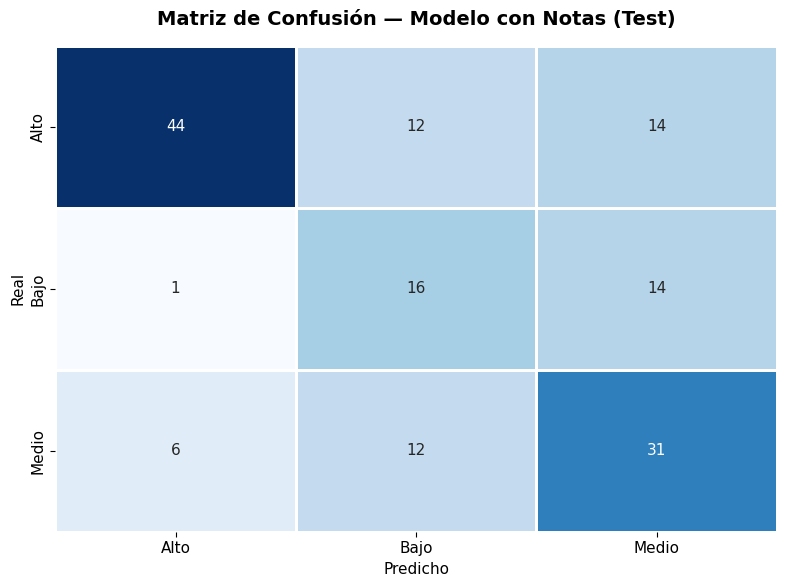

OBSERVACIONES:
   • Diagonal principal = aciertos por clase
   • Fuera de la diagonal = errores de clasificación

Métricas derivadas:
   Alto: 44 aciertos, 26 falsos negativos, 7 falsos positivos
   Bajo: 16 aciertos, 15 falsos negativos, 24 falsos positivos
   Medio: 31 aciertos, 18 falsos negativos, 28 falsos positivos


In [25]:
# GRÁFICO: Matriz de confusión del modelo con notas (heatmap)
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm_B = confusion_matrix(y_B_test, y_B_pred, labels=modelo_B.classes_)
cm_df = pd.DataFrame(cm_B, index=modelo_B.classes_, columns=modelo_B.classes_)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues',
            cbar=False, linewidths=1, linecolor='white', ax=ax)

ax.set_title('Matriz de Confusión — Modelo con Notas (Test)',
             fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Predicho', fontsize=11)
ax.set_ylabel('Real', fontsize=11)

plt.tight_layout()
plt.show()

print("OBSERVACIONES:")
print(f"   • Diagonal principal = aciertos por clase")
print(f"   • Fuera de la diagonal = errores de clasificación")
print(f"\nMétricas derivadas:")
for i, clase in enumerate(modelo_B.classes_):
    tp = cm_B[i, i]
    fn = cm_B[i, :].sum() - tp
    fp = cm_B[:, i].sum() - tp
    print(f"   {clase}: {tp} aciertos, {fn} falsos negativos, {fp} falsos positivos")

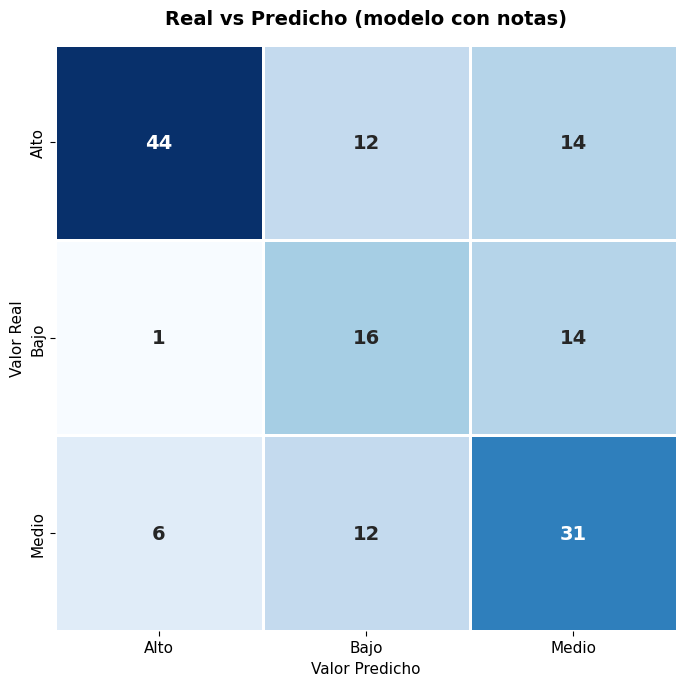

OBSERVACIONES:
   • Diagonal principal = predicción perfecta (aciertos)
   • Fuera de la diagonal = errores de clasificación
   • Si la diagonal está dominante: el modelo acierta mucho
   • Si los errores se alejan de la diagonal: mayor confusión entre clases


In [26]:
# GRÁFICO: Real vs Predicho (versión categórica = heatmap)
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import pandas as pd

cm_B = confusion_matrix(y_B_test, y_B_pred, labels=modelo_B.classes_)
cm_df = pd.DataFrame(cm_B, index=modelo_B.classes_, columns=modelo_B.classes_)

fig, ax = plt.subplots(figsize=(7, 7))

sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues',
            cbar=False, linewidths=1, linecolor='white', ax=ax,
            annot_kws={"fontsize": 14, "fontweight": "bold"})

ax.set_xlabel('Valor Predicho', fontsize=11)
ax.set_ylabel('Valor Real', fontsize=11)
ax.set_title('Real vs Predicho (modelo con notas)', fontsize=14, fontweight='bold', pad=15)

plt.tight_layout()
plt.show()

print("OBSERVACIONES:")
print("   • Diagonal principal = predicción perfecta (aciertos)")
print("   • Fuera de la diagonal = errores de clasificación")
print("   • Si la diagonal está dominante: el modelo acierta mucho")
print("   • Si los errores se alejan de la diagonal: mayor confusión entre clases")

In [28]:
# Guardado de datos
BASE = Path('/content')

# Aqui aseguro que las carpetas existan (por si se reinicio el entorno)
(BASE / 'datos' / 'procesados').mkdir(parents=True, exist_ok=True)
(BASE / 'documentos').mkdir(parents=True, exist_ok=True)

# --- Armado de la tabla de predicciones ---
# Aqui use las predicciones del modelo final (con notas)
resultados = pd.DataFrame({
    'real': y_B_test.values,
    'prediccion': y_B_pred,
    'acierto': (y_B_test.values == y_B_pred).astype(int),
})

# Agrego las probabilidades por clase
proba_df = pd.DataFrame(
    y_B_prob,
    columns=[f'prob_{c}' for c in modelo_B.classes_]
)
resultados = pd.concat([resultados.reset_index(drop=True), proba_df], axis=1)

# --- Guardado de predicciones ---
ruta_pred = BASE / 'datos' / 'procesados' / 'predicciones_guia08.csv'
resultados.to_csv(ruta_pred, index=False, encoding='utf-8')
print(f"Predicciones guardadas: {ruta_pred}")

# --- Guardado de metricas comparativas ---
ruta_metricas = BASE / 'documentos' / 'metricas_guia08.csv'
comparacion.to_csv(ruta_metricas, index=False, encoding='utf-8')
print(f"Métricas guardadas: {ruta_metricas}")

# --- Guardardo de los coeficientes del modelo ---
ruta_coef = BASE / 'documentos' / 'coeficientes_modelo.csv'
df_coef.to_csv(ruta_coef, index=False, encoding='utf-8')
print(f"Coeficientes guardados: {ruta_coef}")

# --- Descarga de archivos ---
from google.colab import files
files.download(str(ruta_pred))
files.download(str(ruta_metricas))
files.download(str(ruta_coef))
print("\nArchivos descargados")

Predicciones guardadas: /content/datos/procesados/predicciones_guia08.csv
Métricas guardadas: /content/documentos/metricas_guia08.csv
Coeficientes guardados: /content/documentos/coeficientes_modelo.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Archivos descargados
